In [279]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import networkx as nx
import sqlite3

con = sqlite3.connect("data/broadband.db")
df = pd.read_csv("./data/bdc_37_fixed_broadband_served_unserved_J26_24oct2026.csv")
county_geoids_df = pd.read_csv("./data/ncstate_county_geoids.csv")

In [280]:
df = df.astype({"location_id": str,"block_geoid": str, "any_dl100_ul20": bool, "wired_dl100_ul20": bool, "terrestrial_dl100_ul20": bool})

In [281]:
df["County GEOID"] = df["block_geoid"].str[2:5]
df["Census Tract GEOID"] = df["block_geoid"].str[:11]

In [282]:
clean_df = df[["block_geoid","County GEOID", "Census Tract GEOID", "any_dl100_ul20", "wired_dl100_ul20", "terrestrial_dl100_ul20"]]

In [283]:
clean_df.head()

,block_geoid,County GEOID,Census Tract GEOID,any_dl100_ul20,wired_dl100_ul20,terrestrial_dl100_ul20
0,371719303011000,171,37171930301,True,False,True
1,371899208002015,189,37189920800,True,True,True
2,371899209003025,189,37189920900,True,True,True
3,371899207022041,189,37189920702,True,True,True
4,371899202001018,189,37189920200,True,True,True


In [284]:
county_geoids_df = county_geoids_df.astype({"FIPS Code": str})
county_geoids_df["FIPS Code"] = county_geoids_df["FIPS Code"].str[2:]
county_geoids_df["County"] = county_geoids_df["County"].str.replace(" County", "").str.strip()
county_geoids_df = county_geoids_df.drop(columns="Tracts")
county_geoids_df.head()

,County,FIPS Code
0,Alamance,001
1,Alexander,003
2,Alleghany,005
3,Anson,007
4,Ashe,009


In [285]:
merged_df = pd.merge(clean_df, county_geoids_df[["County", "FIPS Code"]], left_on="County GEOID", right_on="FIPS Code", how="left")
county_col = merged_df.pop("County")
merged_df = merged_df.drop(columns=["FIPS Code"])
merged_df.insert(1, "County", county_col)
merged_df.head()

,block_geoid,County,County GEOID,Census Tract GEOID,any_dl100_ul20,wired_dl100_ul20,terrestrial_dl100_ul20
0,371719303011000,Surry,171,37171930301,True,False,True
1,371899208002015,Watauga,189,37189920800,True,True,True
2,371899209003025,Watauga,189,37189920900,True,True,True
3,371899207022041,Watauga,189,37189920702,True,True,True
4,371899202001018,Watauga,189,37189920200,True,True,True


In [286]:
merged_df["no_terra_service"] = merged_df["terrestrial_dl100_ul20"] == False

threshold = 15
%store threshold

Stored 'threshold' (int)


In [287]:
fcc_tracts = merged_df.groupby(["County", "Census Tract GEOID"], as_index=False)["no_terra_service"].agg(["size","sum","mean"])
fcc_tracts = fcc_tracts.sort_values(by="mean", ascending=False)
fcc_tracts["pct_without_coverage"] = round(fcc_tracts["mean"] * 100,2)
fcc_tracts = fcc_tracts.rename(columns={"size": "total_locations", "sum": "no_terra_service", "County": "county", "Census Tract GEOID": "geoid"})
fcc_tracts = fcc_tracts.drop(columns="mean")
fcc_tracts.head()

,county,geoid,total_locations,no_terra_service,pct_without_coverage
2239,Swain,37173980200,44,44,100.00
1136,Haywood,37087980100,2,2,100.00
326,Carteret,37031980100,9,9,100.00
940,Granville,37077970704,14,11,78.57
1241,Jackson,37099950800,2987,2234,74.79


In [288]:
by_county = merged_df.groupby("County", as_index=False)["no_terra_service"].agg(["size","sum","mean"])
by_county = by_county.sort_values(by="mean", ascending=False)
by_county["pct_without_coverage"] = round(by_county["mean"] * 100,2)
by_county = by_county.rename(columns={"size": "total_locations", "sum": "no_terra_service", "County": "county"})
by_county = by_county[by_county["total_locations"] >= 100]
by_county = by_county[by_county["pct_without_coverage"] >= threshold]
by_county = by_county.drop(columns="mean")
by_county.head()

,county,total_locations,no_terra_service,pct_without_coverage
37,Graham,5507,2401,43.60
86,Swain,10399,4292,41.27
21,Clay,8106,2646,32.64
49,Jackson,25809,7274,28.18
47,Hyde,3824,1076,28.14


In [289]:
by_tract = merged_df.groupby(["County", "Census Tract GEOID"], as_index=False)["no_terra_service"].agg(["size","sum","mean"])
by_tract = by_tract.sort_values(by="mean", ascending=False)
by_tract["pct_without_coverage"] = round(by_tract["mean"] * 100,2)
by_tract = by_tract.rename(columns={"size": "total_locations", "sum": "no_terra_service", "County": "county", "Census Tract GEOID": "geoid"})
by_tract = by_tract.drop(columns="mean")
by_tract = by_tract[by_tract["total_locations"] >= 100]
by_tract = by_tract[by_tract["pct_without_coverage"] >= threshold]
print(len(by_tract))
by_tract.head()

120


,county,geoid,total_locations,no_terra_service,pct_without_coverage
1241,Jackson,37099950800,2987,2234,74.79
1240,Jackson,37099950700,1911,1427,74.67
2237,Swain,37173960301,2807,1995,71.07
923,Graham,37075920100,2057,1460,70.98
403,Clay,37043950102,1973,1162,58.90


In [290]:
con.execute("DELETE FROM fcc_tracts")

fcc_tracts.to_sql("fcc_tracts", con, if_exists="append", index=False)

2654

Everything past this cell I relied on assistance from Claude to do. Everything was still handwritten I just had Claude walking me through these things while trying to help me understand it.

In [291]:
shape_df = gpd.read_file("data/tl_2020_37_tract.zip").to_crs(32119)
shape_df.head()

,STATEFP,COUNTYFP,TRACTCE,GEOID,NAME,NAMELSAD,MTFCC,FUNCSTAT,ALAND,AWATER,INTPTLAT,INTPTLON,geometry
0,37,141,920300,37141920300,9203,Census Tract 9203,G5020,S,236115472,605423,+34.6713171,-078.0020072,"POLYGON ((686896.998 103394.168, 687069.83 103..."
1,37,141,990100,37141990100,9901,Census Tract 9901,G5020,S,0,133298393,+34.3492469,-077.6031267,"POLYGON ((727968.698 60800.547, 727993.265 608..."
2,37,071,031600,37071031600,316,Census Tract 316,G5020,S,22744042,66304,+35.2681382,-081.2849294,"POLYGON ((398030.831 170385.243, 398034.506 17..."
3,37,071,031800,37071031800,318,Census Tract 318,G5020,S,6071060,8149,+35.2623339,-081.2292201,"POLYGON ((404259.886 170518.838, 404382.904 17..."
4,37,155,961801,37155961801,9618.01,Census Tract 9618.01,G5020,S,103973789,0,+34.6244596,-079.2476138,"POLYGON ((581155.624 94311.87, 581164.57 94327..."


In [292]:
map = pd.merge(shape_df, by_tract, left_on="GEOID", right_on="geoid", how="left")
map.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 2672 entries, 0 to 2671
Data columns (total 18 columns):
 #   Column                Non-Null Count  Dtype   
---  ------                --------------  -----   
 0   STATEFP               2672 non-null   str     
 1   COUNTYFP              2672 non-null   str     
 2   TRACTCE               2672 non-null   str     
 3   GEOID                 2672 non-null   str     
 4   NAME                  2672 non-null   str     
 5   NAMELSAD              2672 non-null   str     
 6   MTFCC                 2672 non-null   str     
 7   FUNCSTAT              2672 non-null   str     
 8   ALAND                 2672 non-null   int64   
 9   AWATER                2672 non-null   int64   
 10  INTPTLAT              2672 non-null   str     
 11  INTPTLON              2672 non-null   str     
 12  geometry              2672 non-null   geometry
 13  county                120 non-null    str     
 14  geoid                 120 non-null    str     
 

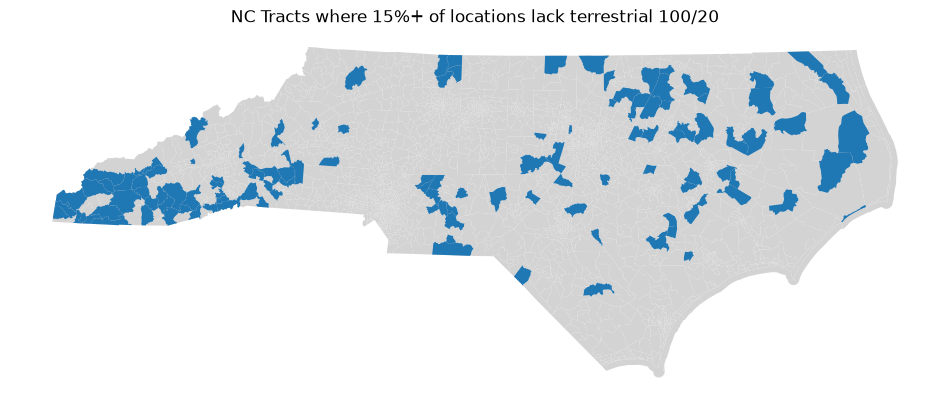

In [293]:
fig, ax = plt.subplots(figsize=(12,6))
map.plot(ax=ax, color="lightgray")

flagged = map[map["pct_without_coverage"].notna()]
flagged.plot(ax=ax, color="tab:blue")

ax.set_axis_off()
ax.set_title(f"NC Tracts where {threshold}%+ of locations lack terrestrial 100/20")

fig.savefig(f"results/flagged_tracts_{threshold}pct.png", dpi=150, bbox_inches="tight")

In [294]:
flagged_cleaned = flagged[["GEOID", "geometry"]]
flagged_cleaned = flagged_cleaned.reset_index(drop=True)

flagged_pairs = gpd.sjoin(flagged_cleaned, flagged_cleaned, predicate="touches")

In [295]:
graph = nx.Graph()

pairs = zip(flagged_pairs["GEOID_left"], flagged_pairs["GEOID_right"])

graph.add_nodes_from(flagged_cleaned["GEOID"])
graph.add_edges_from(pairs)

groups = nx.connected_components(graph)

cluster = {}
for index, group in enumerate(groups, start=1):
    for geoid in group:
        cluster[geoid] = index

flagged["Cluster"] = flagged["GEOID"].map(cluster)

flagged.head()

,STATEFP,COUNTYFP,TRACTCE,GEOID,NAME,NAMELSAD,MTFCC,FUNCSTAT,ALAND,AWATER,INTPTLAT,INTPTLON,geometry,county,geoid,total_locations,no_terra_service,pct_without_coverage,Cluster
17,37,191,000103,37191000103,1.03,Census Tract 1.03,G5020,S,77782716,156895,+35.5488808,-078.0357325,"POLYGON ((690777.911 195652.089, 690828.574 19...",Wayne,37191000103,1283.0,198.0,15.43,1
48,37,015,960100,37015960100,9601,Census Tract 9601,G5020,S,422961809,43116827,+36.1259234,-076.8298463,"POLYGON ((792466.447 263662.602, 792506.214 26...",Bertie,37015960100,3088.0,824.0,26.68,2
50,37,169,070200,37169070200,702,Census Tract 702,G5020,S,193914444,1075423,+36.4620598,-080.2451130,"POLYGON ((490631.61 293495.454, 490633.699 293...",Stokes,37169070200,1988.0,579.0,29.12,3
52,37,169,070600,37169070600,706,Census Tract 706,G5020,S,135971102,1630283,+36.3254971,-080.2035739,"POLYGON ((492563.547 288294.092, 492566.019 28...",Stokes,37169070600,2502.0,444.0,17.75,3
71,37,125,950304,37125950304,9503.04,Census Tract 9503.04,G5020,S,225344221,1523744,+35.3162841,-079.6281541,"POLYGON ((543579.196 178799.986, 543601.716 17...",Moore,37125950304,1586.0,291.0,18.35,4


In [296]:
flagged_clusters = flagged.groupby(["Cluster"], as_index=False).agg({"total_locations": "sum", "no_terra_service": "sum","geoid": "count", "county": lambda x: list(x.unique())})
flagged_clusters["pct_without_coverage"] = round((flagged_clusters["no_terra_service"] / flagged_clusters["total_locations"]) * 100, 2)
flagged_clusters = flagged_clusters.sort_values(["no_terra_service"], ascending=False)
flagged_clusters = flagged_clusters.rename(columns={"geoid": "# of Tracts"})
flagged_clusters.head()

,Cluster,total_locations,no_terra_service,# of Tracts,county,pct_without_coverage
9,10,66793.0,22587.0,28,"[Cherokee, Graham, Jackson, Swain, Macon, Clay...",33.82
8,9,15808.0,3936.0,8,"[Henderson, Polk, Transylvania]",24.90
20,21,14403.0,3341.0,9,"[Nash, Franklin, Halifax, Warren]",23.20
29,30,13245.0,2949.0,8,"[Anson, Stanly, Cabarrus]",22.27
15,16,12429.0,2709.0,9,"[Buncombe, McDowell, Rutherford]",21.80


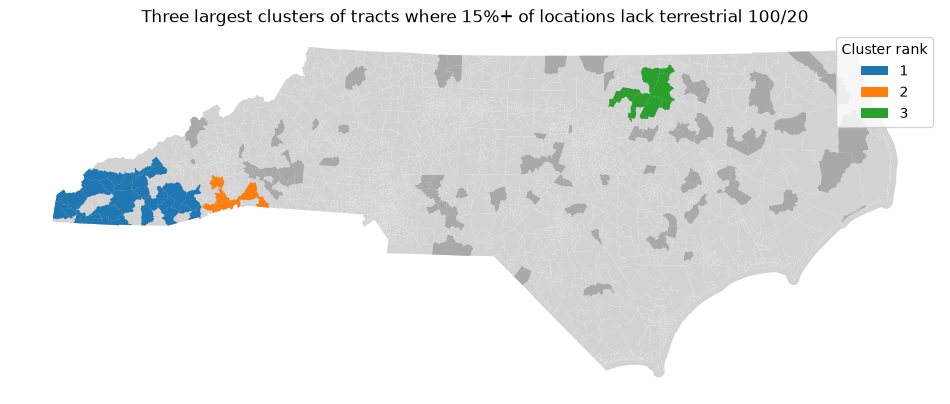

In [297]:
flagged_clusters["Rank"] = range(1, len(flagged_clusters) + 1)
rank_of = dict(zip(flagged_clusters["Cluster"], flagged_clusters["Rank"]))
flagged["Rank"] = flagged["Cluster"].map(rank_of)

fig, ax = plt.subplots(figsize=(12,6))
map.plot(ax=ax, color="lightgray")
flagged.plot(ax=ax, color="darkgray")
top3 = flagged[flagged["Rank"] <= 3]
top3.plot(ax=ax, column="Rank", categorical=True, legend=True, legend_kwds={"title": "Cluster rank"})

ax.set_axis_off()
ax.set_title(f"Three largest clusters of tracts where {threshold}%+ of locations lack terrestrial 100/20")
fig.savefig(f"results/top3_clusters_{threshold}pct.png", dpi=150, bbox_inches="tight")

In [298]:
tract_clusters = flagged[["GEOID", "Cluster", "Rank"]].copy()
tract_clusters["threshold"] = threshold
tract_clusters = tract_clusters.rename(columns={"GEOID": "geoid", "Cluster": "cluster", "Rank": "cluster_rank"})

con.execute("DELETE FROM tract_clusters WHERE threshold = ?", (threshold,))

tract_clusters.to_sql("tract_clusters", con, if_exists="append", index=False)

120

In [299]:
con.close()